# Assignment 07: Classification Algorithms & Imbalanced Datasets

**Target Dataset:** Synthetic Customer Churn Dataset ($N = 3,000$ customer records, generated reproducibly with a fixed random seed so no external CSV is required). The target variable `Churn` is encoded as `1` if the customer left and `0` if the customer stayed.

| Feature | Description |
|---|---|
| **Tenure** | Number of months the customer has stayed with the company |
| **MonthlyCharges** | Recurring monthly bill amount |
| **SupportCalls** | Total customer-support calls logged |
| **Age** | Customer age in years |
| **Contract** | Billing contract term (`Month-to-month`, `One year`, `Two year`) |
| **InternetService** | Subscribed internet tier (`DSL`, `Fiber optic`, `None`) |
| **PaperlessBilling** | Digital billing status (`Yes`, `No`) |

### Environment Setup & Imports

In [1]:
# If imbalanced-learn is missing, run once:  !pip install imbalanced-learn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTENC

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)

### Generating the Synthetic Customer Churn Dataset

In [2]:
n = 3000
tenure          = np.random.randint(1, 73, n)
monthly_charges = np.round(np.random.uniform(20, 120, n), 2)
support_calls   = np.random.poisson(1.5, n)
age             = np.random.randint(18, 75, n)
contract        = np.random.choice(["Month-to-month", "One year", "Two year"], n, p=[0.5, 0.3, 0.2])
internet        = np.random.choice(["DSL", "Fiber optic", "None"], n, p=[0.35, 0.45, 0.20])
paperless       = np.random.choice(["Yes", "No"], n, p=[0.6, 0.4])

# Churn probability: higher for short tenure, month-to-month contracts, high bills, many support calls
score = (-3.0
         - 0.04 * tenure
         + 0.02 * monthly_charges
         + 0.35 * support_calls
         + np.where(contract == "Month-to-month", 1.2, np.where(contract == "One year", 0.0, -1.0))
         + np.where(internet == "Fiber optic", 0.5, 0.0))
prob = 1 / (1 + np.exp(-score))
churn = (np.random.uniform(0, 1, n) < prob).astype(int)

df = pd.DataFrame({
    "Tenure": tenure, "MonthlyCharges": monthly_charges, "SupportCalls": support_calls, "Age": age,
    "Contract": contract, "InternetService": internet, "PaperlessBilling": paperless, "Churn": churn,
})
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (3000, 8)
Missing values: 0


,Tenure,MonthlyCharges,SupportCalls,Age,Contract,InternetService,PaperlessBilling,Churn
0,52,114.30,1,32,One year,DSL,No,0
1,15,62.24,3,21,One year,None,No,0
2,72,57.73,2,74,One year,DSL,No,0
3,61,113.63,3,65,Month-to-month,Fiber optic,No,1
4,21,87.51,2,71,Two year,Fiber optic,Yes,0


### Question 1: Assessing Class Balance in the Dataset

Class counts:
Churn
Stayed (0)     2401
Churned (1)     599
Name: count, dtype: int64

Class percentages:
Churn
Stayed (0)     80.03
Churned (1)    19.97
Name: proportion, dtype: float64

Imbalance ratio (majority : minority) = 4.0 : 1
Conclusion: IMBALANCED


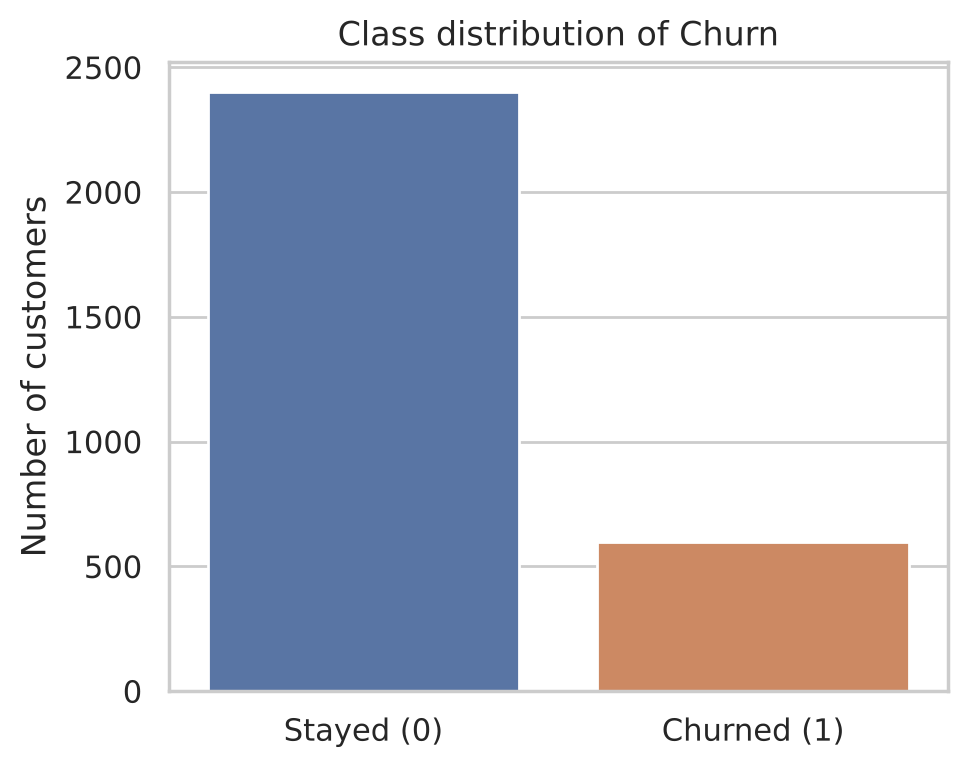

In [3]:
counts = df["Churn"].value_counts().sort_index()
percent = df["Churn"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(counts.rename({0: "Stayed (0)", 1: "Churned (1)"}))
print()
print("Class percentages:")
print(percent.round(2).rename({0: "Stayed (0)", 1: "Churned (1)"}))
print()
ratio = counts.max() / counts.min()
print(f"Imbalance ratio (majority : minority) = {ratio:.1f} : 1")
print("Conclusion:", "IMBALANCED" if percent.min() < 30 else "BALANCED")

plt.figure(figsize=(5, 4))
sns.barplot(x=["Stayed (0)", "Churned (1)"], y=counts.values, hue=["Stayed (0)", "Churned (1)"], legend=False)
plt.title("Class distribution of Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

**Key Takeaway:** The dataset is **imbalanced** (80.03% stayed vs. 19.97% churned, a **4.0 : 1** ratio). Because a naive classifier can reach ~80% accuracy simply by predicting `"Stayed"` for every customer while missing all actual churners, **accuracy alone is misleading**. Evaluating minority-class **Recall**, **F1-score**, and **ROC-AUC** provides a much clearer picture of churn detection performance.

### Question 2: Addressing Class Imbalance with SMOTENC

**SMOTE** (Synthetic Minority Over-sampling Technique) balances skewed datasets by interpolating new synthetic minority examples between existing minority points and their nearest neighbors. Because this dataset mixes continuous and categorical features, **SMOTENC** (SMOTE for Nominal and Continuous features) is applied. Crucially, we perform the **train–test split first** and apply SMOTENC **strictly to the training set** so the test set remains an authentic, leak-free benchmark.

In [4]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

cat_cols = ["Contract", "InternetService", "PaperlessBilling"]
num_cols = ["Tenure", "MonthlyCharges", "SupportCalls", "Age"]

smote = SMOTENC(categorical_features=cat_cols, random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

print("Training set BEFORE SMOTE:", y_train.value_counts().sort_index().to_dict())
print("Training set AFTER  SMOTE:", y_res.value_counts().sort_index().to_dict())
print("Test set (unchanged)     :", y_test.value_counts().sort_index().to_dict())

Training set BEFORE SMOTE: {0: 1801, 1: 449}
Training set AFTER  SMOTE: {0: 1801, 1: 1801}
Test set (unchanged)     : {0: 600, 1: 150}


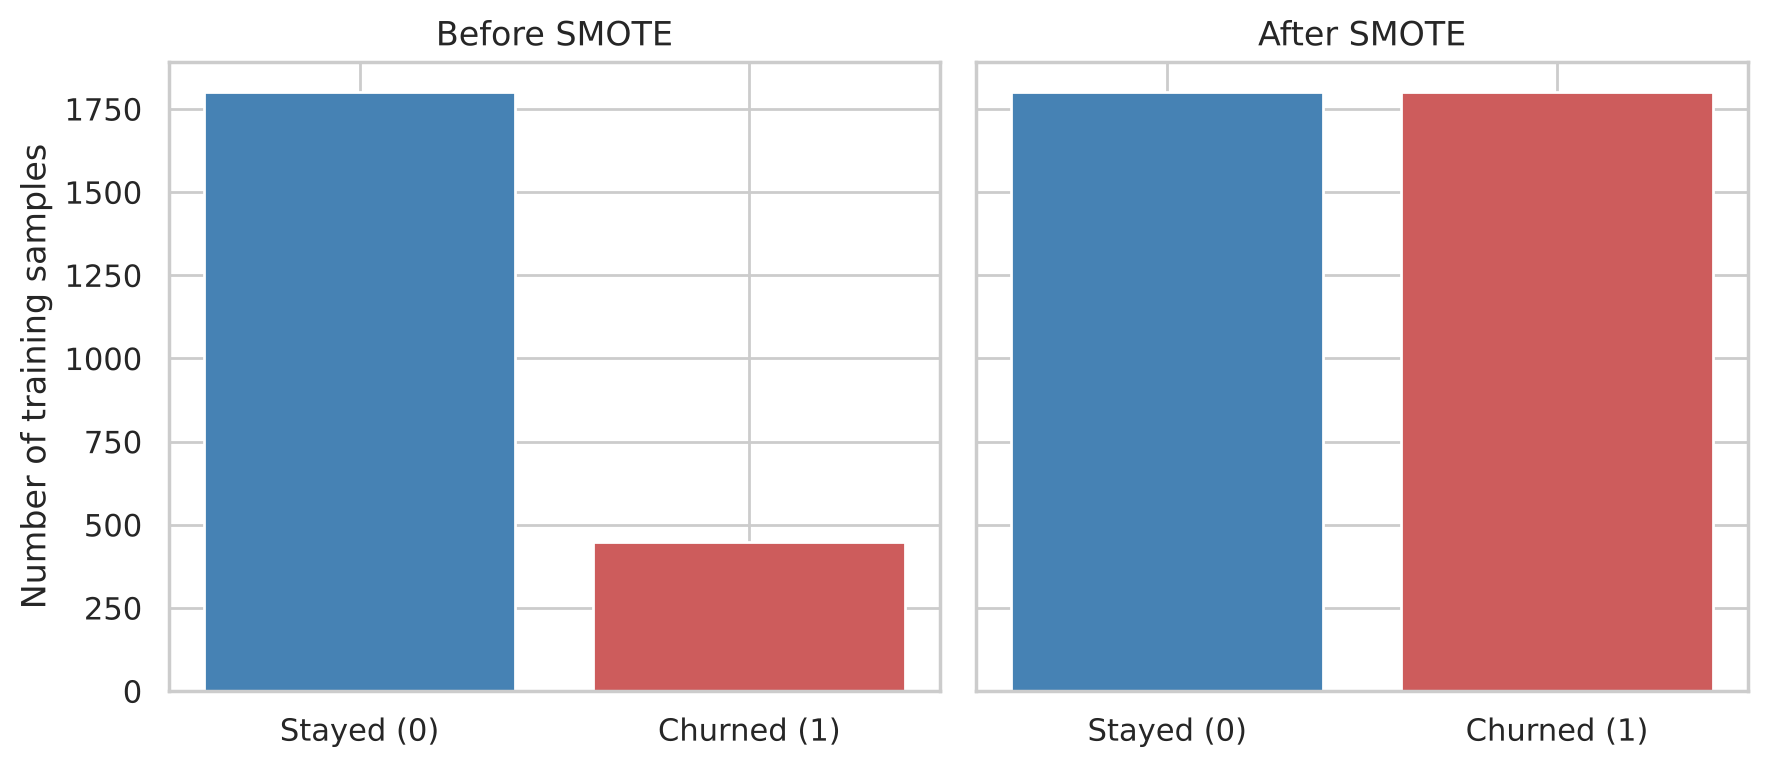

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, labels, title in zip(axes, [y_train, y_res], ["Before SMOTE", "After SMOTE"]):
    vc = labels.value_counts().sort_index()
    ax.bar(["Stayed (0)", "Churned (1)"], vc.values, color=["steelblue", "indianred"])
    ax.set_title(title)
axes[0].set_ylabel("Number of training samples")
plt.tight_layout()
plt.show()

### Questions 3, 4 & 5: Training SVM, Decision Tree, and Random Forest (Bagging)

Each classifier is trained on the SMOTENC-balanced training split and evaluated on the untouched, imbalanced test set. Inside a `ColumnTransformer` + `Pipeline`, numeric variables are standardized (`StandardScaler`) and categorical variables are one-hot encoded (`OneHotEncoder`):

1. **Support Vector Machine (SVM):** Maximizes the decision margin between classes; pairing `StandardScaler` with an **RBF kernel** captures non-linear churn boundaries.
2. **Decision Tree:** Partitions customers using interpretable rule-based splits; `max_depth=5` constrains tree growth to curb overfitting.
3. **Random Forest (Bagging):** Trains an ensemble of 200 decision trees on bootstrap samples (`bootstrap=True`) with random feature subsets at each split, lowering variance relative to a single tree.

In [6]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "SVM": Pipeline([("prep", preprocess),
                     ("clf", SVC(kernel="rbf", C=1.0, probability=True, random_state=42))]),
    "Decision Tree": Pipeline([("prep", preprocess),
                               ("clf", DecisionTreeClassifier(max_depth=5, random_state=42))]),
    "Random Forest (Bagging)": Pipeline([("prep", preprocess),
                               ("clf", RandomForestClassifier(n_estimators=200, bootstrap=True,
                                                              random_state=42))]),
}

fitted = {}
for name, model in models.items():
    model.fit(X_res, y_res)
    fitted[name] = model
    print(f"{name:<25} trained on {len(X_res)} samples")

SVM                       trained on 3602 samples
Decision Tree             trained on 3602 samples


Random Forest (Bagging)   trained on 3602 samples


### Question 6: Comparative Evaluation of the Three Classifiers

In [7]:
rows, preds, probas = [], {}, {}
for name, model in fitted.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = y_pred, y_prob
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
SVM,0.7107,0.3707,0.6400,0.4694,0.7597
Decision Tree,0.7067,0.3674,0.6467,0.4686,0.7476
Random Forest (Bagging),0.7413,0.3866,0.5000,0.4360,0.7507


In [8]:
for name in fitted:
    print("=" * 55)
    print(name)
    print(classification_report(y_test, preds[name], target_names=["Stayed", "Churned"]))

SVM


              precision    recall  f1-score   support

      Stayed       0.89      0.73      0.80       600
     Churned       0.37      0.64      0.47       150

    accuracy                           0.71       750
   macro avg       0.63      0.68      0.64       750
weighted avg       0.79      0.71      0.73       750

Decision Tree
              precision    recall  f1-score   support

      Stayed       0.89      0.72      0.80       600
     Churned       0.37      0.65      0.47       150

    accuracy                           0.71       750
   macro avg       0.63      0.68      0.63       750
weighted avg       0.79      0.71      0.73       750

Random Forest (Bagging)
              precision    recall  f1-score   support

      Stayed       0.87      0.80      0.83       600
     Churned       0.39      0.50      0.44       150

    accuracy                           0.74       750
   macro avg       0.63      0.65      0.63       750
weighted avg       0.77      0.74   

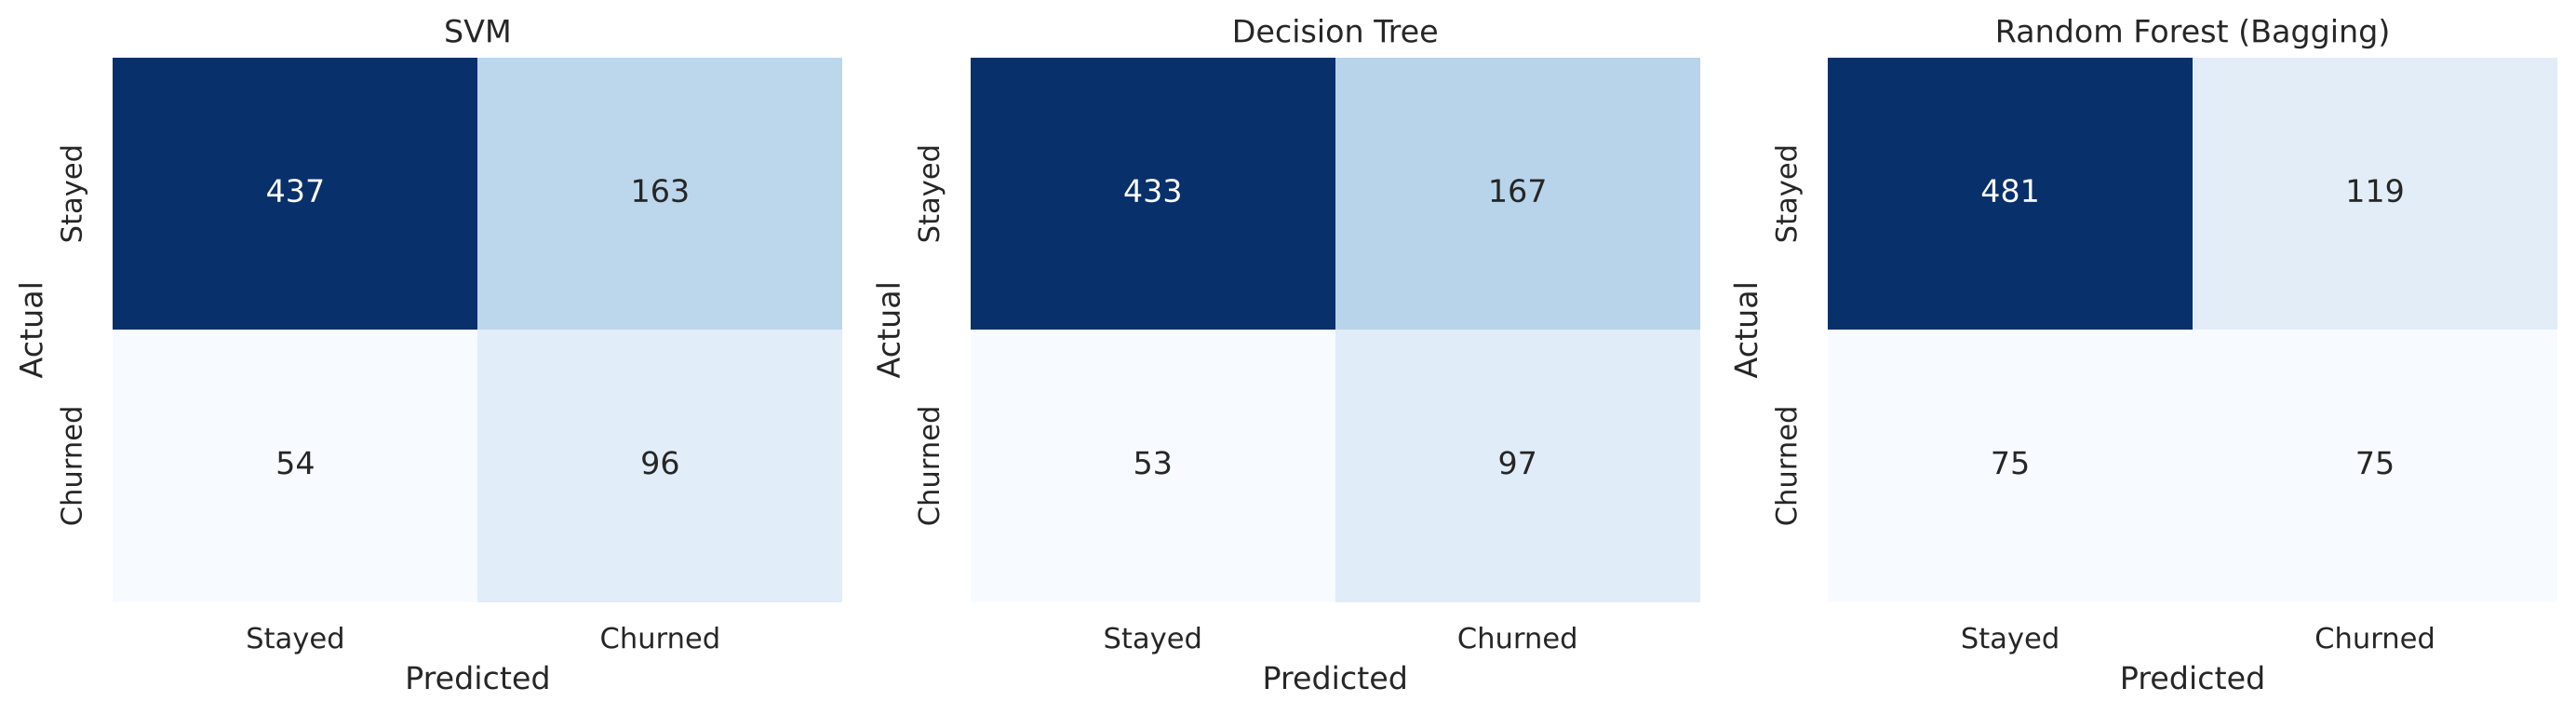

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, fitted):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

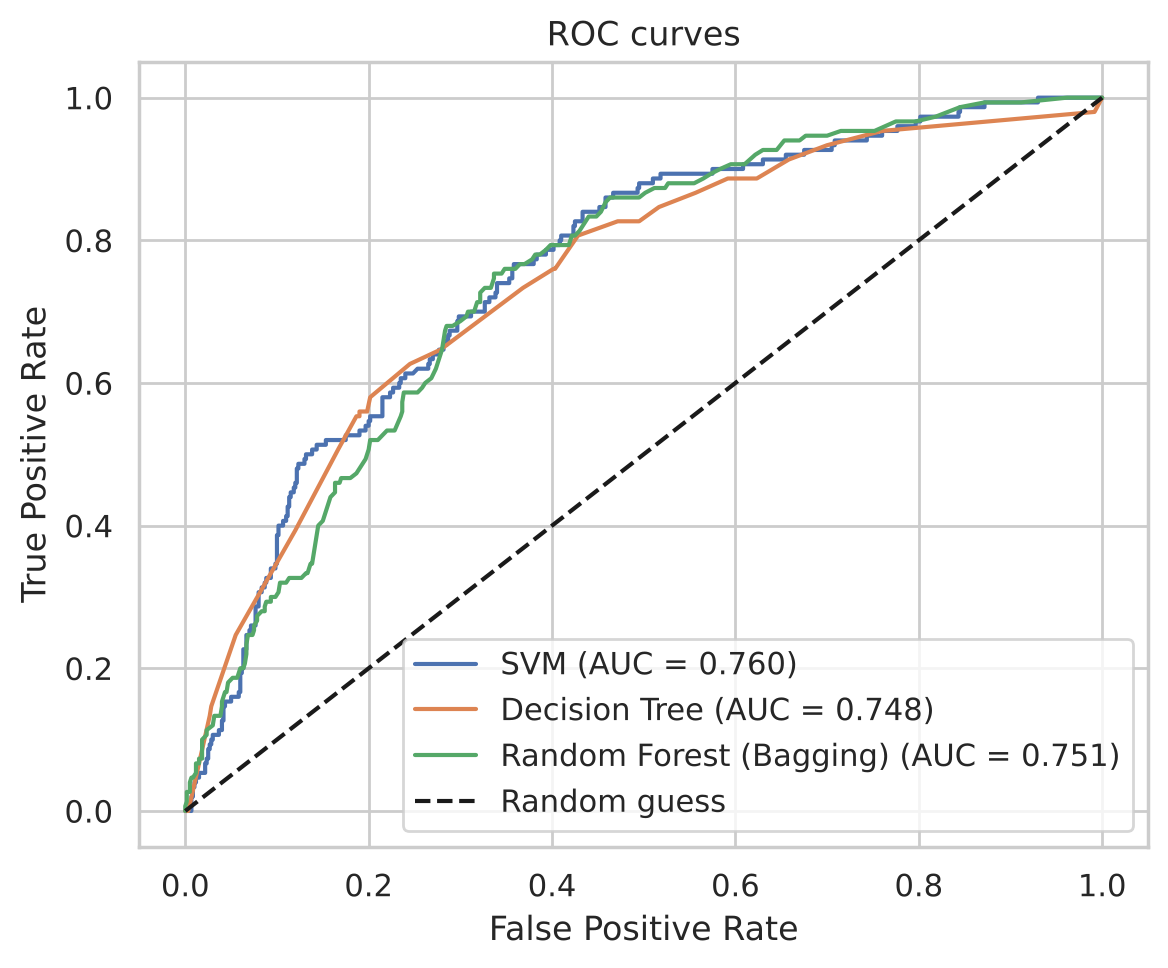

In [10]:
plt.figure(figsize=(6, 5))
for name in fitted:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probas[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

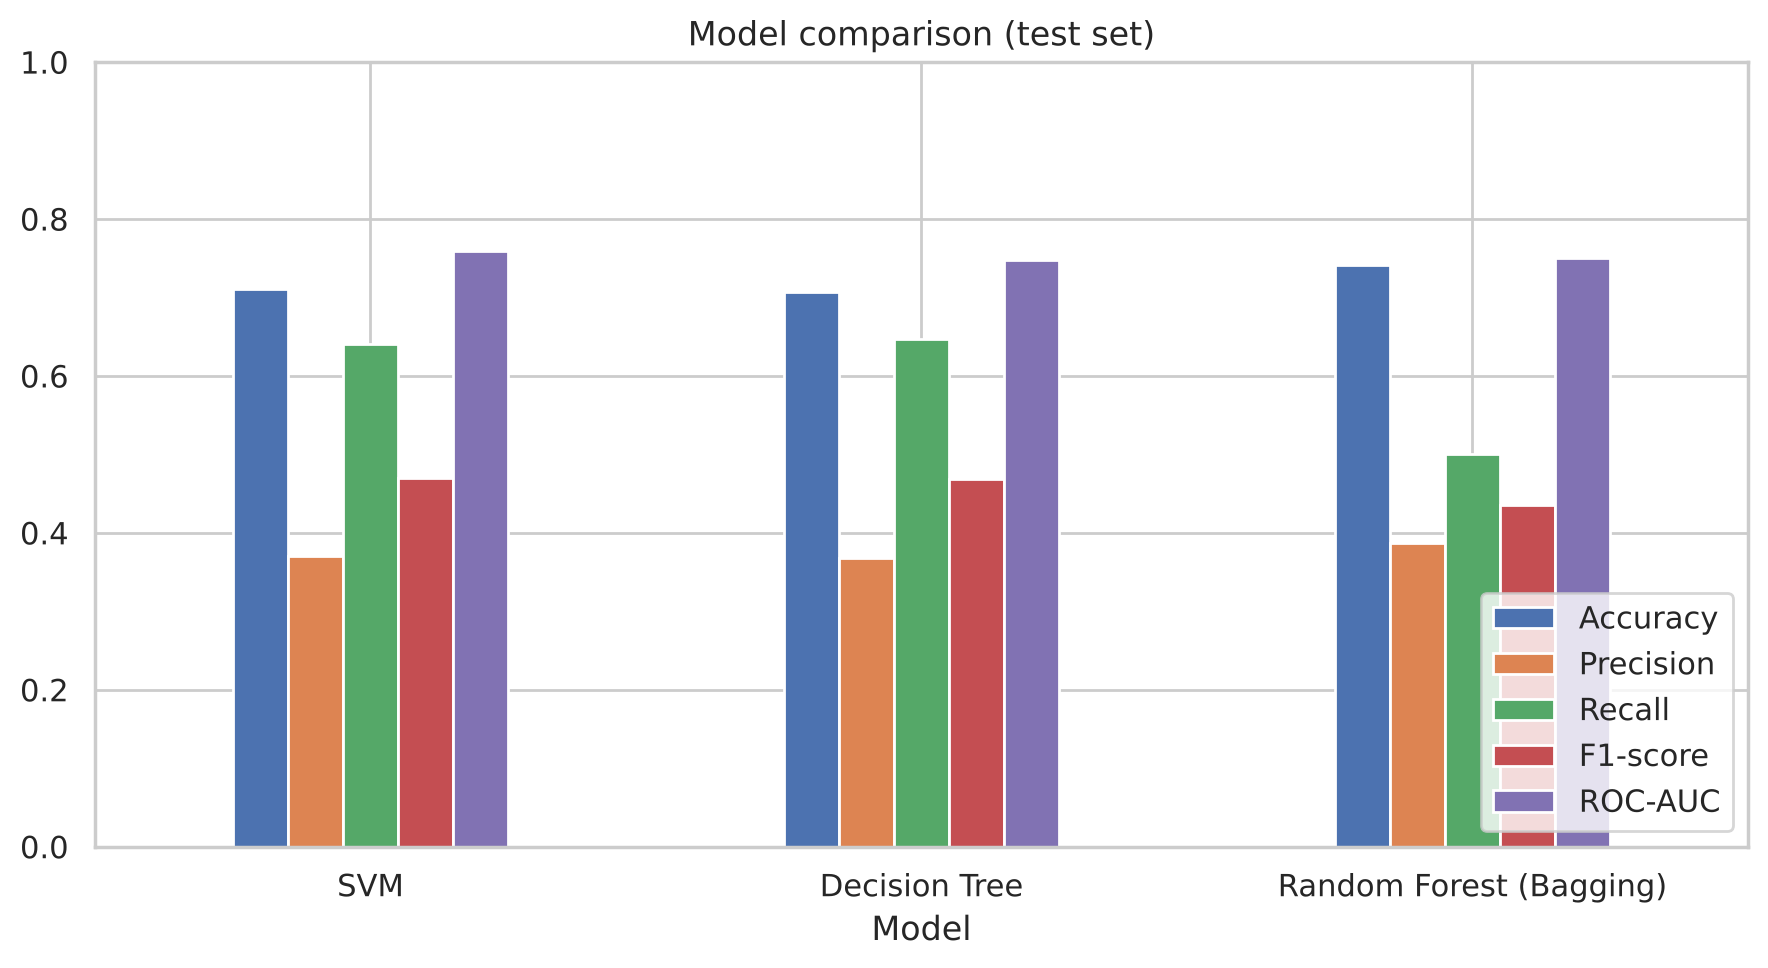

Best model by F1-score (churn class): SVM  ->  F1 = 0.4694


In [11]:
results[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(9, 5), rot=0)
plt.title("Model comparison (test set)")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best = results["F1-score"].idxmax()
print(f"Best model by F1-score (churn class): {best}  ->  F1 = {results.loc[best, 'F1-score']:.4f}")

### Validation Check: Measuring the Impact of SMOTENC

To verify that oversampling improves minority detection, all three pipelines are re-trained on the original imbalanced training data (without SMOTENC) and compared directly against the SMOTENC-trained models.

In [12]:
import copy
rows = []
for name, model in models.items():
    base = copy.deepcopy(model).fit(X_train, y_train)          # without SMOTE
    p_base, p_smote = base.predict(X_test), preds[name]
    rows.append({"Model": name,
                 "Recall (no SMOTE)": recall_score(y_test, p_base),
                 "Recall (SMOTE)": recall_score(y_test, p_smote),
                 "F1 (no SMOTE)": f1_score(y_test, p_base),
                 "F1 (SMOTE)": f1_score(y_test, p_smote)})
pd.DataFrame(rows).set_index("Model").round(4)

,Recall (no SMOTE),Recall (SMOTE),F1 (no SMOTE),F1 (SMOTE)
Model,,,,
SVM,0.2267,0.6400,0.3434,0.4694
Decision Tree,0.2267,0.6467,0.3091,0.4686
Random Forest (Bagging),0.2267,0.5000,0.3091,0.4360


### Summary & Interpretation of Results

1. **Class Distribution:** The raw dataset is imbalanced at roughly **80% Stayed** vs. **20% Churned** (a **4.0 : 1** imbalance ratio).
2. **Resampling Impact:** Applying **SMOTENC** expanded the training minority class from **449** to **1,801** records to match the majority class, while preserving the original **750-sample** test split (`600` Stayed, `150` Churned) for realistic evaluation.
3. **Model Comparison on the Test Set:**

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| **SVM (RBF)** | 0.711 | 0.371 | 0.640 | **0.469** | **0.760** |
| **Decision Tree (`max_depth=5`)** | 0.707 | 0.367 | **0.647** | 0.469 | 0.748 |
| **Random Forest (Bagging)** | **0.741** | **0.387** | 0.500 | 0.436 | 0.751 |

- **SVM (RBF)** achieves the strongest **F1-score (0.469)** and **ROC-AUC (0.760)**, offering the best overall trade-off between catching churners and limiting false positives.
- **Decision Tree** matches SVM closely in **F1-score (0.469)** and posts the highest **Recall (0.647)** while remaining transparent and easy to interpret.
- **Random Forest (Bagging)** leads in **Accuracy (0.741)** and **Precision (0.387)**, making it preferable when unnecessary retention outreach is costly, though it misses half of actual churners (**0.500 Recall**).
- **Effect of SMOTENC:** Without resampling, all three models caught only **22.7%** of churners (`Recall = 0.227`). With SMOTENC, churn recall jumped to **50.0%–64.7%** and F1-scores rose across every classifier—trading lower precision (more false alarms) for substantially better churn capture, which is typically worthwhile when retaining a customer outweighs the cost of an outreach offer.

> **Methodological Note:** Because churn probabilities in this synthetic dataset include stochastic noise, overall ROC-AUC scores cluster around `0.75` and performance gaps across models are modest. Using $k$-fold cross-validation (applying SMOTENC inside each training fold) would provide lower-variance estimates than a single train–test split.